In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import cv2

from torch.utils.data import DataLoader

In [18]:
PROJECT_ROOT = Path("../")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

In [20]:
from src.datasets.sarrarp50_dataset import SARRARP50Dataset

In [9]:
DATASET_ROOT = Path(
    "/work/tesi_cmininno/dataset/SARRARP50"
)

TRAIN_ROOT = DATASET_ROOT / "train"
VAL_ROOT = DATASET_ROOT / "val"

print("Dataset:", DATASET_ROOT)
print("Train:", TRAIN_ROOT.exists())
print("Val:", VAL_ROOT.exists())

Dataset: /work/tesi_cmininno/dataset/SARRARP50
Train: True
Val: True


In [12]:
train_videos = sorted(
    p.name
    for p in TRAIN_ROOT.iterdir()
    if p.is_dir() and p.name.startswith("video_")
)

val_videos = sorted(
    p.name
    for p in VAL_ROOT.iterdir()
    if p.is_dir() and p.name.startswith("video_")
)

print("Train videos:")
print(train_videos)

print("\nNumber of train videos:", len(train_videos))

print("\nValidation videos:")
print(val_videos)

print("\nNumber of validation videos:", len(val_videos))

Train videos:
['video_01', 'video_02', 'video_03', 'video_04', 'video_05', 'video_06', 'video_07', 'video_08', 'video_09', 'video_10', 'video_11_1', 'video_11_2', 'video_12', 'video_13', 'video_14', 'video_15_1', 'video_15_2', 'video_16', 'video_17_1', 'video_17_2', 'video_18', 'video_19', 'video_20', 'video_21', 'video_22', 'video_23', 'video_24', 'video_25', 'video_26', 'video_27', 'video_28', 'video_29_1', 'video_29_2', 'video_30', 'video_31', 'video_32', 'video_33', 'video_34', 'video_35', 'video_36', 'video_37', 'video_38', 'video_39', 'video_40']

Number of train videos: 44

Validation videos:
['video_41', 'video_42', 'video_43', 'video_44', 'video_45', 'video_46', 'video_47', 'video_48', 'video_49', 'video_50']

Number of validation videos: 10


In [13]:
video_dir = TRAIN_ROOT / "video_01"

video_path = video_dir / "video_left.avi"
segmentation_dir = video_dir / "segmentation"

print("Video:", video_path)
print("Video exists:", video_path.exists())

print("Segmentation:", segmentation_dir)
print("Segmentation exists:", segmentation_dir.exists())

Video: /work/tesi_cmininno/dataset/SARRARP50/train/video_01/video_left.avi
Video exists: True
Segmentation: /work/tesi_cmininno/dataset/SARRARP50/train/video_01/segmentation
Segmentation exists: True


In [14]:
mask_paths = sorted(segmentation_dir.glob("*.png"))

print("Number of masks:", len(mask_paths))
print("First masks:")

for path in mask_paths[:10]:
    print(path.name)

Number of masks: 563
First masks:
000000000.png
000000060.png
000000120.png
000000180.png
000000240.png
000000300.png
000000360.png
000000420.png
000000480.png
000000540.png


In [21]:
dataset = SARRARP50Dataset(
    root=DATASET_ROOT,
    split="train",
)

print("Dataset length:", len(dataset))

Dataset length: 13043


In [23]:
sample = dataset[0]

print(sample.keys())

dict_keys(['image', 'mask', 'video', 'frame'])


In [24]:
image = sample["image"]
mask = sample["mask"]

print("Video:", sample["video"])
print("Frame:", sample["frame"])

print("\nImage:")
print("  shape:", image.shape)
print("  dtype:", image.dtype)

print("\nMask:")
print("  shape:", mask.shape)
print("  dtype:", mask.dtype)
print("  unique:", np.unique(mask))

Video: video_01
Frame: 0

Image:
  shape: (1080, 1920, 3)
  dtype: uint8

Mask:
  shape: (1080, 1920)
  dtype: uint8
  unique: [0 1 2 3 5]


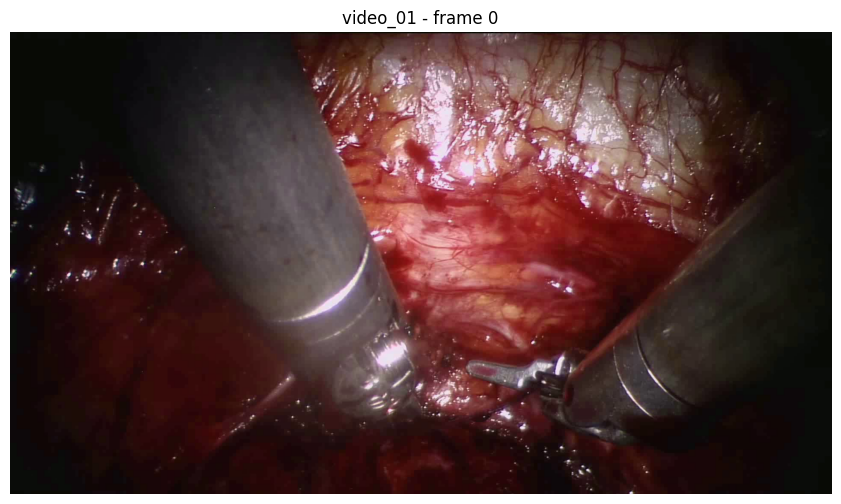

In [26]:
plt.figure(figsize=(12, 6))

plt.imshow(image)
plt.axis("off")
plt.title(
    f"{sample['video']} - frame {sample['frame']}"
)

plt.show()

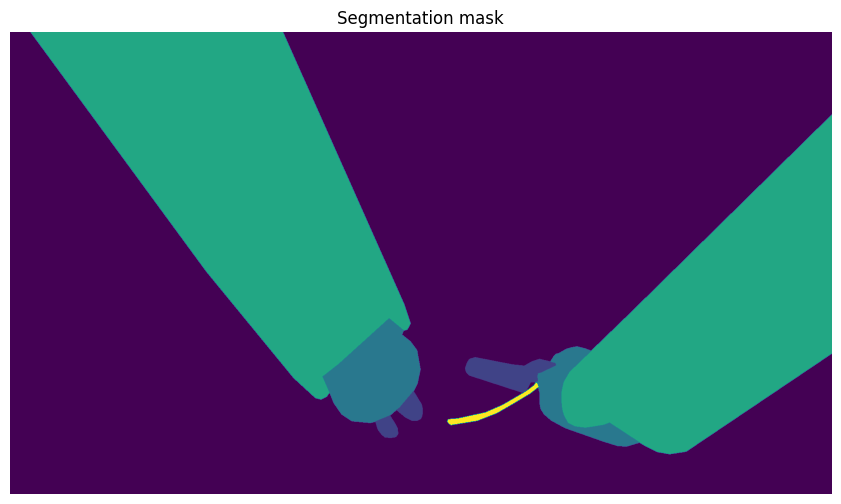

In [27]:
plt.figure(figsize=(12, 6))

plt.imshow(mask)
plt.axis("off")
plt.title("Segmentation mask")

plt.show()

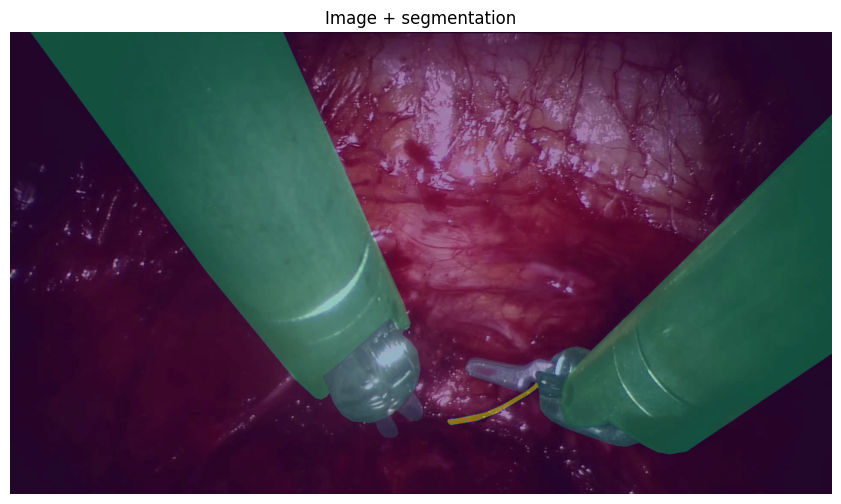

In [28]:
plt.figure(figsize=(12, 6))

plt.imshow(image)
plt.imshow(mask, alpha=0.45)

plt.axis("off")
plt.title("Image + segmentation")

plt.show()

In [29]:
class_names = SARRARP50Dataset.CLASS_NAMES

present_classes = np.unique(mask)

for class_id in present_classes:
    print(
        f"{class_id:2d} - {class_names[class_id]}"
    )

 0 - Background
 1 - Tool clasper
 2 - Tool wrist
 3 - Tool shaft
 5 - Thread


In [30]:
values, counts = np.unique(
    mask,
    return_counts=True,
)

total_pixels = mask.size

for class_id, count in zip(values, counts):

    percentage = 100.0 * count / total_pixels

    print(
        f"{class_id:2d} "
        f"{class_names[class_id]:20s} "
        f"{count:10d} pixels "
        f"({percentage:6.2f}%)"
    )

 0 Background              1393747 pixels ( 67.21%)
 1 Tool clasper              14221 pixels (  0.69%)
 2 Tool wrist                49435 pixels (  2.38%)
 3 Tool shaft               613415 pixels ( 29.58%)
 5 Thread                     2782 pixels (  0.13%)


In [31]:
indices = np.linspace(
    0,
    len(dataset) - 1,
    5,
    dtype=int,
)

for idx in indices:

    sample = dataset[idx]

    print(
        f"idx={idx:5d} | "
        f"video={sample['video']:10s} | "
        f"frame={sample['frame']:6d} | "
        f"image={sample['image'].shape} | "
        f"mask={sample['mask'].shape} | "
        f"classes={np.unique(sample['mask'])}"
    )

idx=    0 | video=video_01   | frame=     0 | image=(1080, 1920, 3) | mask=(1080, 1920) | classes=[0 1 2 3 5]
idx= 3260 | video=video_10   | frame=  3120 | image=(1080, 1920, 3) | mask=(1080, 1920) | classes=[0 1 2 3 4 5 8]
idx= 6521 | video=video_20   | frame= 12240 | image=(1080, 1920, 3) | mask=(1080, 1920) | classes=[0 1 2 3 4 5 9]
idx= 9781 | video=video_31   | frame=  4560 | image=(1080, 1920, 3) | mask=(1080, 1920) | classes=[0 1 2 3 4 5 8 9]
idx=13042 | video=video_40   | frame= 16500 | image=(1080, 1920, 3) | mask=(1080, 1920) | classes=[0 1 2 3 4 5 7 8 9]


In [32]:
loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(loader))

In [33]:
print(batch.keys())

print("Image batch:", batch["image"].shape)
print("Mask batch:", batch["mask"].shape)

dict_keys(['image', 'mask', 'video', 'frame'])
Image batch: torch.Size([2, 1080, 1920, 3])
Mask batch: torch.Size([2, 1080, 1920])


In [34]:
train_dataset = SARRARP50Dataset(
    root=DATASET_ROOT,
    split="train",
)

print("Train samples:", len(train_dataset))

Train samples: 13043


In [35]:
val_dataset = SARRARP50Dataset(
    root=DATASET_ROOT,
    split="val",
)

print("Val samples:", len(val_dataset))

Val samples: 3252


In [36]:
print("Train videos:")
print(sorted(set(s["video"] for s in train_dataset.samples)))

print("\nVal videos:")
print(sorted(set(s["video"] for s in val_dataset.samples)))

Train videos:
['video_01', 'video_02', 'video_03', 'video_04', 'video_05', 'video_06', 'video_07', 'video_08', 'video_09', 'video_10', 'video_11_1', 'video_11_2', 'video_12', 'video_13', 'video_14', 'video_15_1', 'video_15_2', 'video_16', 'video_17_1', 'video_17_2', 'video_18', 'video_19', 'video_20', 'video_21', 'video_22', 'video_23', 'video_24', 'video_25', 'video_26', 'video_27', 'video_28', 'video_29_1', 'video_29_2', 'video_30', 'video_31', 'video_32', 'video_33', 'video_34', 'video_35', 'video_36', 'video_37', 'video_38', 'video_39', 'video_40']

Val videos:
['video_41', 'video_42', 'video_43', 'video_44', 'video_45', 'video_46', 'video_47', 'video_48', 'video_49', 'video_50']
